# Challenge 2 — Pipeline de Machine Learning
## Tipo B: Infecciones Respiratorias Agudas (IRAs)

- Curso: Machine Learning
- Unidad: Fundamentos de IA y Búsqueda
- Plataforma: Google Colab
- Caso: Tipo B — Infecciones Respiratorias Agudas.
- Institución: Universidad Peruana Cayetano Heredia (UPCH)
- Estudiante: Juan Vidal Berrocal Ccapcha

**Alcance:** para la parte predictiva se utilizará regresión lineal con un conjunto pequeño de datos sintéticos, porque la rúbrica solicita un modelo de regresión. No se utilizarán algoritmos de ensamble ni técnicas avanzadas de preprocesamiento que no forman parte de los temas compar

**Importante:** los valores oficiales de contexto se mantienen separados de los datos sintéticos. El modelo de regresión es una demostración académica; no pronostica casos reales del Perú.

## Fuentes y referencias — inicio

1. Universidad Peruana Cayetano Heredia (UPCH). *Challenge 1 (Individual): Pipeline de Machine Learning*. Documento de instrucciones proporcionado para el curso.
2. UPCH, Fundamentos de IA y Búsqueda. *Búsqueda en Profundidad (DFS) y Búsqueda en Anchura (BFS)*, Sesión 3, material de clase proporcionado.
3. UPCH, Fundamentos de IA y Búsqueda. *Búsqueda Exhaustiva (BF), Hill Climbing y A* Search*, Sesión 4, material de clase proporcionado.
4. UPCH, Fundamentos de Machine Learning. *Tipos de Aprendizaje*, Sesión 5, material de clase proporcionado.
5. UPCH, Fundamentos de Machine Learning. *Clasificación vs Regresión y Clustering vs Reducción*, Sesión 6, material de clase proporcionado.
6. UPCH, Fundamentos de Machine Learning. *Regresión Lineal, Regresión No Lineal y Regresión Logística*, Sesión 7, material de clase proporcionado.
7. Infografía *Infecciones Respiratorias Agudas (IRA) y Neumonía en menores de 5 años en el Perú*, proporcionada para el caso.

**Procedencia de los datos:** las cifras epidemiológicas de contexto se transcriben de la infografía del caso. El pequeño conjunto utilizado para practicar regresión se genera artificialmente dentro de este notebook y no procede del MINSA ni de pacientes reales. Portal institucional del MINSA: https://www.gob.pe/minsa

## 1. Presentación del caso, problema y justificación de IA/ML

La infografía entregada para el caso reporta, en menores de cinco años:

- **Episodios de IRA:** 1 003 178 (2023), 883 959 (2024) y 824 978 (2025).
- **Defunciones por neumonía:** 113 (2023), 82 (2024) y 51 (2025).

En el periodo mostrado ambas cifras disminuyen. Sin embargo, tres datos anuales agregados no explican por qué ocurrió la disminución, no permiten comparar regiones ni establecer causalidad.

### Problema que se busca resolver

**¿Cómo explorar de manera ordenada distintas tareas de análisis de la información disponible y elaborar un resumen epidemiológico, y cómo demostrar una regresión lineal para estimar una cantidad numérica usando datos sintéticos relacionados con el caso?**

### ¿Por qué puede ayudar la IA?

Los algoritmos de búsqueda permiten representar y recorrer alternativas de análisis de forma sistemática. El aprendizaje automático puede ajustar una relación entre variables cuando existe un conjunto de ejemplos con valores conocidos. En este trabajo, la búsqueda organiza rutas de análisis y la regresión lineal se utiliza únicamente como ejercicio didáctico; no se pretende diagnosticar, explicar causas ni emitir un pronóstico sanitario real.

### Tarea de Machine Learning

- **Tipo de aprendizaje:** supervisado, porque para cada ejemplo sintético se conoce el valor objetivo.
- **Tarea:** regresión, porque se estima una cantidad numérica, no una categoría.
- **Modelo elegido:** regresión lineal simple, apropiada para demostrar la relación entre un índice temporal y una variable numérica mediante una recta, y porque fue abordada en la sesión 7.
- **Limitación:** los datos de entrenamiento son artificiales; no constituyen una serie oficial de IRAs.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from itertools import combinations
from sklearn.linear_model import LinearRegression

np.random.seed(42)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Datos de contexto de la infografía

Los valores siguientes se transcriben de la imagen entregada para el Challenge. Se utilizan solo para describir el contexto; tres observaciones anuales no son suficientes para entrenar un modelo predictivo robusto.

,anio,episodios_ira,defunciones_neumonia
0,2023,1003178,113
1,2024,883959,82
2,2025,824978,51


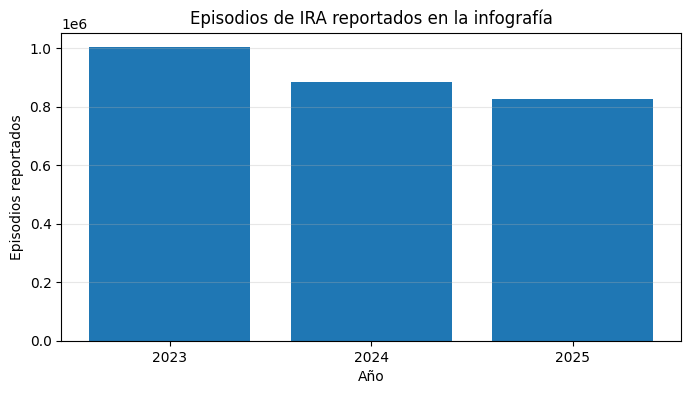

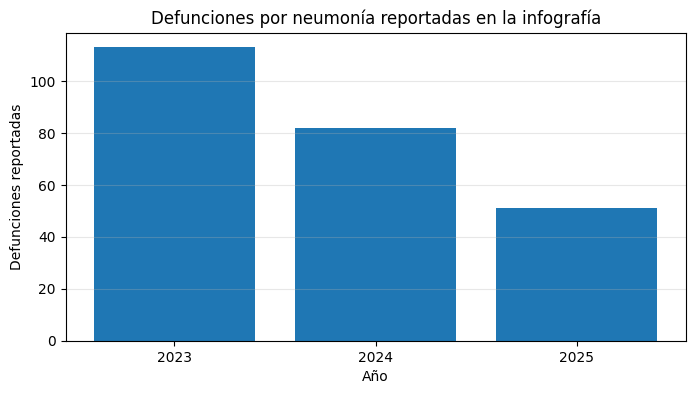

In [ ]:
contexto = pd.DataFrame({
    "anio": [2023, 2024, 2025],
    "episodios_ira": [1003178, 883959, 824978],
    "defunciones_neumonia": [113, 82, 51]
})

display(contexto)

plt.figure(figsize=(8, 4))
plt.bar(contexto["anio"].astype(str), contexto["episodios_ira"])
plt.title("Episodios de IRA reportados en la infografía")
plt.xlabel("Año")
plt.ylabel("Episodios reportados")
plt.grid(axis="y", alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(contexto["anio"].astype(str), contexto["defunciones_neumonia"])
plt.title("Defunciones por neumonía reportadas en la infografía")
plt.xlabel("Año")
plt.ylabel("Defunciones reportadas")
plt.grid(axis="y", alpha=0.3)
plt.show()

## 3. Espacio de estados: definición formal

Este espacio representa **rutas alternativas de trabajo analítico** para elaborar un resumen a partir de la infografía. Es un modelo conceptual del estudiante, no un protocolo del MINSA ni una recomendación clínica.

- **Estado inicial:** `Datos_disponibles`, es decir, las cifras anuales de la infografía están disponibles.
- **Estados intermedios:** analizar episodios de IRA, analizar defunciones por neumonía o identificar brechas de información.
- **Estado de integración:** integrar hallazgos de la tarea elegida.
- **Estado objetivo:** producir un resumen epidemiológico que incluya observaciones y limitaciones.
- **Operadores:** `analizar_episodios`, `analizar_defunciones`, `identificar_brechas` e `integrar_hallazgos`; cada operador cambia de un estado al siguiente según las conexiones del grafo.
- **Restricciones:** no inventar cifras oficiales ausentes; no confundir datos sintéticos con datos reales; no atribuir causalidad a una tendencia descriptiva; toda ruta debe terminar en la integración y el resumen.
- **Criterio de solución:** encontrar una ruta válida desde el estado inicial hasta el estado objetivo. Para A*, además, se asignan costos didácticos explícitos a las transiciones.

BFS y DFS permiten comparar estrategias de exploración; fuerza bruta enumera las rutas simples; A* considera el costo acumulado y una heurística. Los resultados describen el grafo definido, no determinan qué medida sanitaria es mejor.

In [ ]:
estados = [
    "Datos_disponibles",
    "Analizar_episodios_IRA",
    "Analizar_defunciones_neumonia",
    "Identificar_brechas",
    "Integrar_hallazgos",
    "Resumen_epidemiologico"
]

conexiones = {
    "Datos_disponibles": [
        "Analizar_episodios_IRA",
        "Analizar_defunciones_neumonia",
        "Identificar_brechas"
    ],
    "Analizar_episodios_IRA": ["Integrar_hallazgos"],
    "Analizar_defunciones_neumonia": ["Integrar_hallazgos"],
    "Identificar_brechas": ["Integrar_hallazgos"],
    "Integrar_hallazgos": ["Resumen_epidemiologico"],
    "Resumen_epidemiologico": []
}

inicio = "Datos_disponibles"
objetivo = "Resumen_epidemiologico"

print("Estados del problema:")
for estado in estados:
    print("-", estado.replace("_", " "))

Estados del problema:
- Datos disponibles
- Analizar episodios IRA
- Analizar defunciones neumonia
- Identificar brechas
- Integrar hallazgos
- Resumen epidemiologico


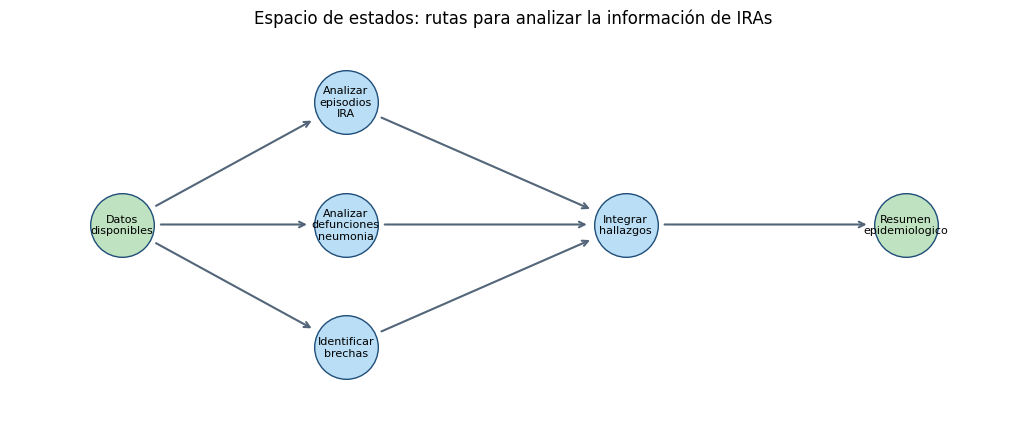

In [ ]:
# Diagrama del espacio de estados
posiciones = {
    "Datos_disponibles": (0, 0),
    "Analizar_episodios_IRA": (2, 1.4),
    "Analizar_defunciones_neumonia": (2, 0),
    "Identificar_brechas": (2, -1.4),
    "Integrar_hallazgos": (4.5, 0),
    "Resumen_epidemiologico": (7, 0)
}

plt.figure(figsize=(13, 5))
for origen, destinos in conexiones.items():
    for destino in destinos:
        x1, y1 = posiciones[origen]
        x2, y2 = posiciones[destino]
        plt.annotate("", xy=(x2, y2), xytext=(x1, y1),
                     arrowprops=dict(arrowstyle="->", lw=1.5, color="#526579",
                                     shrinkA=28, shrinkB=28))

for estado, (x, y) in posiciones.items():
    color = "#b9def5" if estado not in [inicio, objetivo] else "#bfe3c0"
    plt.scatter(x, y, s=2100, color=color, edgecolor="#1f4e79", zorder=3)
    etiqueta = estado.replace("_", "\n")
    plt.text(x, y, etiqueta, ha="center", va="center", fontsize=8, zorder=4)

plt.title("Espacio de estados: rutas para analizar la información de IRAs")
plt.xlim(-1, 8)
plt.ylim(-2.2, 2.2)
plt.axis("off")
plt.show()

## 4. Búsqueda en Anchura (BFS)

BFS utiliza una cola y explora primero los estados más cercanos al inicio. En un grafo no ponderado, encuentra una ruta con el menor número de transiciones.

In [ ]:
def bfs(inicio, objetivo, grafo):
    cola = deque([[inicio]])
    visitados = []
    orden_exploracion = []

    while cola:
        ruta = cola.popleft()
        estado = ruta[-1]
        if estado in visitados:
            continue
        visitados.append(estado)
        orden_exploracion.append(estado)
        if estado == objetivo:
            return ruta, orden_exploracion
        for vecino in grafo[estado]:
            if vecino not in visitados:
                cola.append(ruta + [vecino])
    return None, orden_exploracion

ruta_bfs, explorados_bfs = bfs(inicio, objetivo, conexiones)
print("Ruta encontrada por BFS:")
print(" -> ".join(n.replace("_", " ") for n in ruta_bfs))
print("Estados visitados hasta encontrar la meta:", len(explorados_bfs))
print("Orden de exploración:", " -> ".join(n.replace("_", " ") for n in explorados_bfs))
print("Interpretación: BFS explora por niveles y, en este grafo no ponderado, encuentra una ruta con el menor número de transiciones.")

Ruta encontrada por BFS:
Datos disponibles -> Analizar episodios IRA -> Integrar hallazgos -> Resumen epidemiologico
Estados visitados hasta encontrar la meta: 6
Orden de exploración: Datos disponibles -> Analizar episodios IRA -> Analizar defunciones neumonia -> Identificar brechas -> Integrar hallazgos -> Resumen epidemiologico
Interpretación: BFS explora por niveles y, en este grafo no ponderado, encuentra una ruta con el menor número de transiciones.


## 5. Búsqueda en Profundidad (DFS)

DFS utiliza una pila y avanza por una rama antes de retroceder. Puede encontrar una ruta, pero no garantiza la ruta con menos transiciones.

In [ ]:
def dfs(inicio, objetivo, grafo):
    pila = [[inicio]]
    visitados = []
    orden_exploracion = []

    while pila:
        ruta = pila.pop()
        estado = ruta[-1]
        if estado in visitados:
            continue
        visitados.append(estado)
        orden_exploracion.append(estado)
        if estado == objetivo:
            return ruta, orden_exploracion
        # Se invierte para mantener un orden de exploración reproducible.
        for vecino in reversed(grafo[estado]):
            if vecino not in visitados:
                pila.append(ruta + [vecino])
    return None, orden_exploracion

ruta_dfs, explorados_dfs = dfs(inicio, objetivo, conexiones)
print("Ruta encontrada por DFS:")
print(" -> ".join(n.replace("_", " ") for n in ruta_dfs))
print("Estados visitados hasta encontrar la meta:", len(explorados_dfs))
print("Orden de exploración:", " -> ".join(n.replace("_", " ") for n in explorados_dfs))
print("Interpretación: DFS avanza por una rama antes de retroceder; la ruta depende del orden de los vecinos y no garantiza menor costo.")

Ruta encontrada por DFS:
Datos disponibles -> Analizar episodios IRA -> Integrar hallazgos -> Resumen epidemiologico
Estados visitados hasta encontrar la meta: 4
Orden de exploración: Datos disponibles -> Analizar episodios IRA -> Integrar hallazgos -> Resumen epidemiologico
Interpretación: DFS avanza por una rama antes de retroceder; la ruta depende del orden de los vecinos y no garantiza menor costo.


### Comparación BFS y DFS

BFS utiliza una cola y explora primero los estados más cercanos al inicio; DFS utiliza una pila y avanza por una rama antes de retroceder. En este grafo, ambos pueden llegar al estado objetivo, pero el orden de exploración puede hacer que seleccionen distintas rutas de análisis.

La ruta encontrada no demuestra que una tarea epidemiológica sea más importante que otra: solo muestra el comportamiento del algoritmo sobre el grafo definido.

In [ ]:
print("COMPARACIÓN BFS vs. DFS")
print("BFS:", " -> ".join(n.replace("_", " ") for n in ruta_bfs), "| transiciones:", len(ruta_bfs) - 1, "| estados explorados:", len(explorados_bfs))
print("DFS:", " -> ".join(n.replace("_", " ") for n in ruta_dfs), "| transiciones:", len(ruta_dfs) - 1, "| estados explorados:", len(explorados_dfs))
print("\nConclusión:")
print("- BFS encuentra una ruta con el menor número de transiciones porque el grafo no está ponderado para BFS.")
print("- DFS puede encontrar otra ruta según el orden de exploración; no optimiza costos.")
print("- En este ejemplo, las rutas representan tareas de análisis posibles, no decisiones clínicas ni prioridades de salud pública.")

COMPARACIÓN BFS vs. DFS
BFS: Datos disponibles -> Analizar episodios IRA -> Integrar hallazgos -> Resumen epidemiologico | transiciones: 3 | estados explorados: 6
DFS: Datos disponibles -> Analizar episodios IRA -> Integrar hallazgos -> Resumen epidemiologico | transiciones: 3 | estados explorados: 4

Conclusión:
- BFS encuentra una ruta con el menor número de transiciones porque el grafo no está ponderado para BFS.
- DFS puede encontrar otra ruta según el orden de exploración; no optimiza costos.
- En este ejemplo, las rutas representan tareas de análisis posibles, no decisiones clínicas ni prioridades de salud pública.


## 6. Búsqueda por fuerza bruta (BF)

La búsqueda por fuerza bruta enumera las rutas simples posibles del estado inicial a la meta. En este grafo pequeño permite comparar todas las alternativas. Una ruta simple no repite estados; esa restricción evita ciclos en la enumeración.

In [ ]:
def generar_rutas(actual, objetivo, grafo, ruta=None):
    if ruta is None:
        ruta = []
    ruta = ruta + [actual]

    if actual == objetivo:
        return [ruta]

    rutas = []
    for vecino in grafo[actual]:
        if vecino not in ruta:
            rutas.extend(generar_rutas(vecino, objetivo, grafo, ruta))
    return rutas

rutas = generar_rutas(inicio, objetivo, conexiones)
print("Rutas posibles:")
for i, ruta in enumerate(rutas, start=1):
    print(f"Ruta {i}: " + " -> ".join(ruta))
print("Total de rutas simples:", len(rutas))
if rutas:
    ruta_menor = min(rutas, key=len)
    print("Ruta con menos transiciones:", " -> ".join(ruta_menor))
    print("Transiciones de esa ruta:", len(ruta_menor) - 1)
print("Interpretación: la fuerza bruta enumera todas las rutas simples posibles en este grafo pequeño; puede ser costosa si el espacio crece.")

Rutas posibles:
Ruta 1: Datos_disponibles -> Analizar_episodios_IRA -> Integrar_hallazgos -> Resumen_epidemiologico
Ruta 2: Datos_disponibles -> Analizar_defunciones_neumonia -> Integrar_hallazgos -> Resumen_epidemiologico
Ruta 3: Datos_disponibles -> Identificar_brechas -> Integrar_hallazgos -> Resumen_epidemiologico
Total de rutas simples: 3
Ruta con menos transiciones: Datos_disponibles -> Analizar_episodios_IRA -> Integrar_hallazgos -> Resumen_epidemiologico
Transiciones de esa ruta: 3
Interpretación: la fuerza bruta enumera todas las rutas simples posibles en este grafo pequeño; puede ser costosa si el espacio crece.


## 7. A* Search: búsqueda informada

A* prioriza los estados mediante **f(n) = g(n) + h(n)**: `g(n)` es el costo acumulado y `h(n)` una estimación del costo restante. En este ejemplo, los costos son **unidades didácticas de esfuerzo**, no costos sanitarios.

Se utiliza una heurística sencilla: desde los estados de análisis se estima que faltan al menos dos unidades (integración + resumen), desde `Integrar_hallazgos` falta una y desde la meta cero. Estos valores son una demostración del algoritmo y no representan mediciones reales.

In [ ]:
# Costos ilustrativos de transiciones (no son costos sanitarios)
costos = {
    ("Datos_disponibles", "Analizar_episodios_IRA"): 2,
    ("Datos_disponibles", "Analizar_defunciones_neumonia"): 2,
    ("Datos_disponibles", "Identificar_brechas"): 2,
    ("Analizar_episodios_IRA", "Integrar_hallazgos"): 1,
    ("Analizar_defunciones_neumonia", "Integrar_hallazgos"): 1,
    ("Identificar_brechas", "Integrar_hallazgos"): 2,
    ("Integrar_hallazgos", "Resumen_epidemiologico"): 1
}

def costo_transicion(origen, destino):
    return costos[(origen, destino)]

def heuristica(estado, objetivo):
    # Estimación didáctica del costo restante; h(meta)=0.
    estimaciones = {
        "Datos_disponibles": 3,
        "Analizar_episodios_IRA": 2,
        "Analizar_defunciones_neumonia": 2,
        "Identificar_brechas": 3,
        "Integrar_hallazgos": 1,
        "Resumen_epidemiologico": 0
    }
    return estimaciones[estado]

def a_estrella(inicio, objetivo, grafo):
    abiertos = [(heuristica(inicio, objetivo), 0, [inicio])]
    mejor_costo = {inicio: 0}
    explorados = []
    while abiertos:
        abiertos.sort(key=lambda elemento: elemento[0], reverse=True)
        f, g, ruta = abiertos.pop()
        actual = ruta[-1]
        if actual in explorados:
            continue
        explorados.append(actual)
        if actual == objetivo:
            return ruta, g, explorados
        for vecino in grafo[actual]:
            nuevo_g = g + costo_transicion(actual, vecino)
            if nuevo_g < mejor_costo.get(vecino, float("inf")):
                mejor_costo[vecino] = nuevo_g
                nuevo_f = nuevo_g + heuristica(vecino, objetivo)
                abiertos.append((nuevo_f, nuevo_g, ruta + [vecino]))
    return None, float("inf"), explorados

ruta_a, costo_a, explorados_a = a_estrella(inicio, objetivo, conexiones)
print("Ruta A*:", " -> ".join(n.replace("_", " ") for n in ruta_a))
print("Costo didáctico total:", costo_a)
print("Estados explorados:", len(explorados_a))
print("Interpretación: A* selecciona una ruta de menor costo según los costos ilustrativos definidos. Si cambian esos costos, podría cambiar la ruta elegida.")

Ruta A*: Datos disponibles -> Analizar defunciones neumonia -> Integrar hallazgos -> Resumen epidemiologico
Costo didáctico total: 4
Estados explorados: 4
Interpretación: A* selecciona una ruta de menor costo según los costos ilustrativos definidos. Si cambian esos costos, podría cambiar la ruta elegida.


## 8. Hill Climbing: demostración conceptual

Hill Climbing mejora una solución mediante cambios pequeños y conserva los que mejoran una función objetivo. Para no presentar una fórmula artificial como si describiera la salud pública, esta sección se mantiene como **demostración independiente del algoritmo**: sus valores no representan prioridades reales de prevención ni una intervención contra las IRAs.

In [ ]:
# Función matemática artificial para demostrar Hill Climbing.
# Los parámetros no representan medidas ni prioridades sanitarias reales.
def objetivo_demo(x, y):
    return -((x - 0.7)**2 + (y - 0.3)**2)

solucion = np.array([0.2, 0.8])
paso = 0.1
valor_actual = objetivo_demo(solucion[0], solucion[1])

for _ in range(30):
    vecinos = [
        solucion + np.array([paso, 0]),
        solucion + np.array([-paso, 0]),
        solucion + np.array([0, paso]),
        solucion + np.array([0, -paso])
    ]
    vecinos = [np.clip(v, 0, 1) for v in vecinos]
    mejor_vecino = max(vecinos, key=lambda v: objetivo_demo(v[0], v[1]))
    valor_vecino = objetivo_demo(mejor_vecino[0], mejor_vecino[1])
    if valor_vecino > valor_actual:
        solucion = mejor_vecino
        valor_actual = valor_vecino
    else:
        break

print("Solución matemática ilustrativa:", solucion)
print("Valor de la función objetivo:", round(valor_actual, 4))
print("Esta demostración explica el algoritmo; no produce una recomendación sanitaria.")

Solución matemática ilustrativa: [0.7 0.3]
Valor de la función objetivo: -0.0
Esta demostración explica el algoritmo; no produce una recomendación sanitaria.


## 9. Dataset sintético para regresión lineal

La infografía proporciona solo tres observaciones anuales de episodios de IRA. Con tan pocos puntos no sería responsable afirmar que se entrenó y validó un modelo predictivo confiable. La rúbrica permite utilizar datos sintéticos o referenciales, así que se crea una serie mensual **artificial de 36 puntos** para practicar el pipeline.

- `mes`: índice temporal simulado (1–36).
- `episodios_sinteticos_miles`: índice artificial de episodios expresado en miles sintéticos.
- La dirección descendente se inspira únicamente en la tendencia general de la infografía; los valores mensuales y su escala se generaron artificialmente.
- Estos datos no son registros del MINSA, no corresponden a pacientes y no permiten predecir la incidencia real del Perú.

In [ ]:
rng = np.random.default_rng(42)

datos = pd.DataFrame({
    "mes": np.arange(1, 37)
})

# Serie artificial: tendencia descendente más variación aleatoria moderada.
ruido = rng.normal(0, 2.0, size=len(datos))
datos["episodios_sinteticos_miles"] = 100 - 0.8 * datos["mes"] + ruido
datos["episodios_sinteticos_miles"] = datos["episodios_sinteticos_miles"].clip(lower=1).round(2)

display(datos.head(10))
print("Cantidad de registros sintéticos:", len(datos))

,mes,episodios_sinteticos_miles
0,1,99.81
1,2,96.32
2,3,99.10
3,4,98.68
4,5,92.10
5,6,92.60
6,7,94.66
7,8,92.97
8,9,92.77
9,10,90.29


Cantidad de registros sintéticos: 36


## 10. Revisión sencilla de datos y visualización

Se revisan los tipos de datos, posibles valores faltantes y el patrón general de la serie sintética. Este paso ayuda a entender los datos antes de entrenar el modelo. La tabla y el gráfico de esta sección son artificiales, no registros oficiales.

Tipos de datos:
mes                             int64
episodios_sinteticos_miles    float64
dtype: object
\nValores faltantes:
mes                           0
episodios_sinteticos_miles    0
dtype: int64
\nResumen numérico:


,mes,episodios_sinteticos_miles
count,36.000000,36.000000
mean,18.500000,85.348333
std,10.535654,8.230245
min,1.000000,71.170000
25%,9.750000,78.980000
50%,18.500000,84.765000
75%,27.250000,92.225000
max,36.000000,99.810000


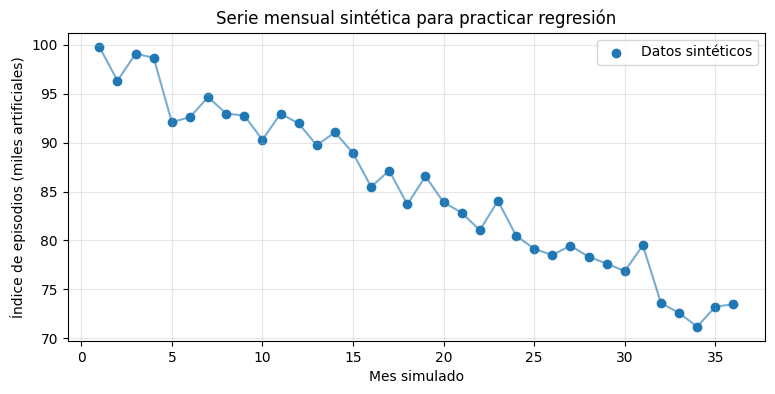

In [ ]:
print("Tipos de datos:")
print(datos.dtypes)

print("\\nValores faltantes:")
print(datos.isna().sum())

print("\\nResumen numérico:")
display(datos.describe())

plt.figure(figsize=(9, 4))
plt.scatter(datos["mes"], datos["episodios_sinteticos_miles"], label="Datos sintéticos")
plt.plot(datos["mes"], datos["episodios_sinteticos_miles"], alpha=0.6)
plt.title("Serie mensual sintética para practicar regresión")
plt.xlabel("Mes simulado")
plt.ylabel("Índice de episodios (miles artificiales)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 11. Entrenamiento, justificación e interpretación de regresión lineal

Se elige **regresión lineal simple** porque el objetivo didáctico es estimar una variable numérica (`episodios_sinteticos_miles`) a partir de una entrada numérica (`mes`) y visualizar una tendencia mediante una recta. Es un modelo introductorio coherente con los contenidos de la sesión 7. No se elige clasificación porque no se predice una etiqueta o categoría.

- **Entrada (`X`):** mes simulado.
- **Objetivo (`y`):** índice sintético de episodios, en miles artificiales.
- **Entrenamiento:** primeros 27 meses (75 % de los registros).
- **Prueba:** últimos 9 meses (25 %), reservados para una evaluación posterior en el orden temporal.

La división conserva el orden de la serie para evitar mezclar registros futuros y pasados en este ejemplo.

In [ ]:
# División temporal: 27 registros para entrenar y 9 para probar.
X = datos[["mes"]]
y = datos["episodios_sinteticos_miles"]

X_train = X.iloc[:27]
y_train = y.iloc[:27]
X_test = X.iloc[27:]
y_test = y.iloc[27:]

modelo = LinearRegression()
modelo.fit(X_train, y_train)

predicciones_test = modelo.predict(X_test)
datos["prediccion_modelo"] = modelo.predict(X)

print("Ecuación estimada: y =", round(modelo.intercept_, 3), "+", round(modelo.coef_[0], 3), "* mes")
print("Pendiente:", round(modelo.coef_[0], 3), "unidades sintéticas por mes")
print("\\nPredicciones para los últimos 9 registros:")
resultado_test = pd.DataFrame({
    "mes": X_test["mes"].values,
    "valor_sintetico_observado": y_test.values,
    "valor_estimado": np.round(predicciones_test, 2)
})
display(resultado_test)

Ecuación estimada: y = 99.609 + -0.776 * mes
Pendiente: -0.776 unidades sintéticas por mes
\nPredicciones para los últimos 9 registros:


,mes,valor_sintetico_observado,valor_estimado
0,28,78.33,77.89
1,29,77.63,77.11
2,30,76.86,76.34
3,31,79.48,75.56
4,32,73.59,74.78
5,33,72.58,74.01
6,34,71.17,73.23
7,35,73.23,72.46
8,36,73.46,71.68


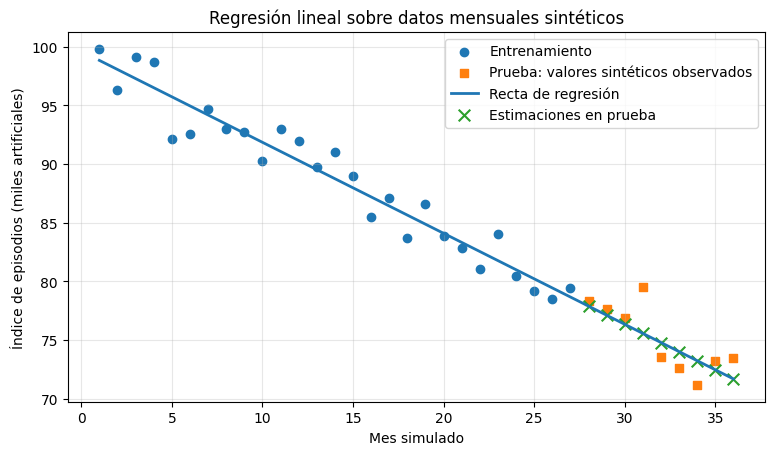

In [ ]:
plt.figure(figsize=(9, 4.8))
plt.scatter(X_train["mes"], y_train, label="Entrenamiento")
plt.scatter(X_test["mes"], y_test, label="Prueba: valores sintéticos observados", marker="s")
plt.plot(datos["mes"], datos["prediccion_modelo"], label="Recta de regresión", linewidth=2)
plt.scatter(X_test["mes"], predicciones_test, label="Estimaciones en prueba", marker="x", s=70)
plt.title("Regresión lineal sobre datos mensuales sintéticos")
plt.xlabel("Mes simulado")
plt.ylabel("Índice de episodios (miles artificiales)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Evaluación básica del modelo

Se calculan MAE, RMSE y R² usando únicamente los nueve registros reservados para prueba. Estas métricas describen el ajuste sobre los datos sintéticos; no evalúan el desempeño de un sistema epidemiológico real.

In [ ]:
errores = y_test.to_numpy() - predicciones_test

mae = np.mean(np.abs(errores))
rmse = np.sqrt(np.mean(errores ** 2))
ss_res = np.sum(errores ** 2)
ss_tot = np.sum((y_test.to_numpy() - np.mean(y_test.to_numpy())) ** 2)
r2_test = 1 - (ss_res / ss_tot) if ss_tot != 0 else np.nan

metricas = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Valor": [mae, rmse, r2_test],
    "Interpretación": [
        "Error absoluto medio en unidades sintéticas",
        "Error cuadrático medio, penaliza más los errores grandes",
        "Proporción de variabilidad explicada en el conjunto de prueba"
    ]
})
display(metricas)

print(f"MAE = {mae:.2f}: error absoluto medio en la escala sintética.")
print(f"RMSE = {rmse:.2f}: error que penaliza más las desviaciones grandes.")
print(f"R² = {r2_test:.3f}: se interpreta solo como evaluación de la serie sintética.")

,Métrica,Valor,Interpretación
0,MAE,1.404596,Error absoluto medio en unidades sintéticas
1,RMSE,1.750760,"Error cuadrático medio, penaliza más los error..."
2,R²,0.602255,Proporción de variabilidad explicada en el con...


MAE = 1.40: error absoluto medio en la escala sintética.
RMSE = 1.75: error que penaliza más las desviaciones grandes.
R² = 0.602: se interpreta solo como evaluación de la serie sintética.


### Interpretación de resultados y límites

- La **pendiente** indica el cambio promedio estimado del índice sintético por cada mes simulado; no es una tasa oficial de cambio de IRAs.
- En el gráfico, los puntos de entrenamiento se usan para ajustar la recta; los puntos de prueba son datos sintéticos que no se utilizaron en el ajuste; las cruces muestran las estimaciones para esos meses.
- **MAE** resume el error absoluto medio y **RMSE** penaliza más los errores grandes. **R²** compara el modelo con una predicción basada en la media; puede ser negativo si el modelo rinde peor que esa referencia en los datos de prueba.
- La calidad de estas métricas solo se refiere a la pequeña serie artificial. No demuestra capacidad predictiva para la salud pública.
- Para un pronóstico real se necesitaría una serie mensual oficial suficientemente extensa, documentada y con variables relevantes; además, habría que evaluar el modelo con datos reales reservados.

## 12. Resumen del pipeline de razonamiento y búsqueda

1. **Problema:** elaborar un resumen descriptivo de la evolución de episodios de IRA y defunciones por neumonía, identificando además la información que falta.
2. **Espacio de estados:** definir estado inicial, alternativas de análisis, integración y estado objetivo; explicitar operadores y restricciones.
3. **Exploración:** representar el grafo y listar las transiciones disponibles.
4. **Búsqueda:** aplicar BFS, DFS, fuerza bruta y A*; comparar rutas, cantidad de transiciones, estados explorados y costo didáctico cuando corresponda.
5. **Resultado:** producir una ruta de trabajo analítico y un resumen descriptivo limitado a las cifras disponibles. Los algoritmos organizan el recorrido; no prueban causas ni seleccionan intervenciones sanitarias.

## 13. Conclusiones

1. Se presentó el caso de las IRAs en menores de cinco años con las cifras transcritas de la infografía.
2. Se definió un espacio de estados con rutas alternativas para analizar episodios de IRA, defunciones por neumonía o brechas de información, y luego integrar hallazgos.
3. Se implementaron BFS, DFS, fuerza bruta y A* para explorar rutas en el grafo; los costos de A* son didácticos y no representan costos sanitarios.
4. Se mostró Hill Climbing como demostración matemática independiente, sin atribuirle recomendaciones de salud pública.
5. Se seleccionó regresión lineal porque el objetivo demostrativo es estimar una cantidad numérica.
6. Se generó una serie mensual sintética, se entrenó una regresión lineal y se interpretaron un gráfico y métricas de evaluación.
7. Los resultados de regresión no son pronósticos epidemiológicos reales. Para ese objetivo se necesitarían datos oficiales mensuales, suficientemente extensos y documentados.

## Fuentes y referencias — final

- Universidad Peruana Cayetano Heredia. *Challenge 1 (Individual): Pipeline de Machine Learning*, rúbrica proporcionada para el curso.
- UPCH. *Búsqueda en Profundidad (DFS) y Búsqueda en Anchura (BFS)*, Sesión 3.
- UPCH. *Búsqueda Exhaustiva (BF), Hill Climbing y A* Search*, Sesión 4.
- UPCH. *Tipos de Aprendizaje*, Sesión 5.
- UPCH. *Clasificación vs Regresión y Clustering vs Reducción*, Sesión 6.
- UPCH. *Regresión Lineal, Regresión No Lineal y Regresión Logística*, Sesión 7.
- Infografía *Infecciones Respiratorias Agudas (IRA) y Neumonía en menores de 5 años en el Perú*, proporcionada para el caso.
- Ministerio de Salud del Perú (MINSA), portal institucional: https://www.gob.pe/minsa

**Declaración de datos:** las cifras del DataFrame `contexto` proceden de la infografía proporcionada. El DataFrame `datos` es generado artificialmente para enseñar regresión lineal. No se utilizaron registros de pacientes ni datos mensuales oficiales.

## Verificación final frente a la rúbrica

- **Presentación del caso y problema:** cifras del caso, pregunta definida y justificación del uso de búsqueda/ML.
- **Espacio de estados:** estados, operadores, restricciones y diagrama.
- **Razonamiento, búsqueda y resultados:** problema, espacio, exploración, algoritmos y resultados interpretados.
- **Modelo predictivo y visualización:** tarea de regresión justificada, dataset sintético identificado como tal, entrenamiento/prueba, métricas y gráfico interpretativo.

**Alcance:** este notebook demuestra conceptos académicos de búsqueda y regresión lineal. No es un sistema sanitario operativo ni genera pronósticos oficiales.